# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [16]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 16 / 8 / (1024 ** 2)

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** What would go wrong if anisotropic voxels were ignored?

**Your answer:** The software would treat the 1.0 mm slice spacing as if it were the same as the 0.5 mm in-plane spacing.
Coronal and sagittal anatomy would look stretched or squashed, and distances or shapes could be measured incorrectly.
Using the real voxel spacing keeps the patient’s anatomy proportional.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

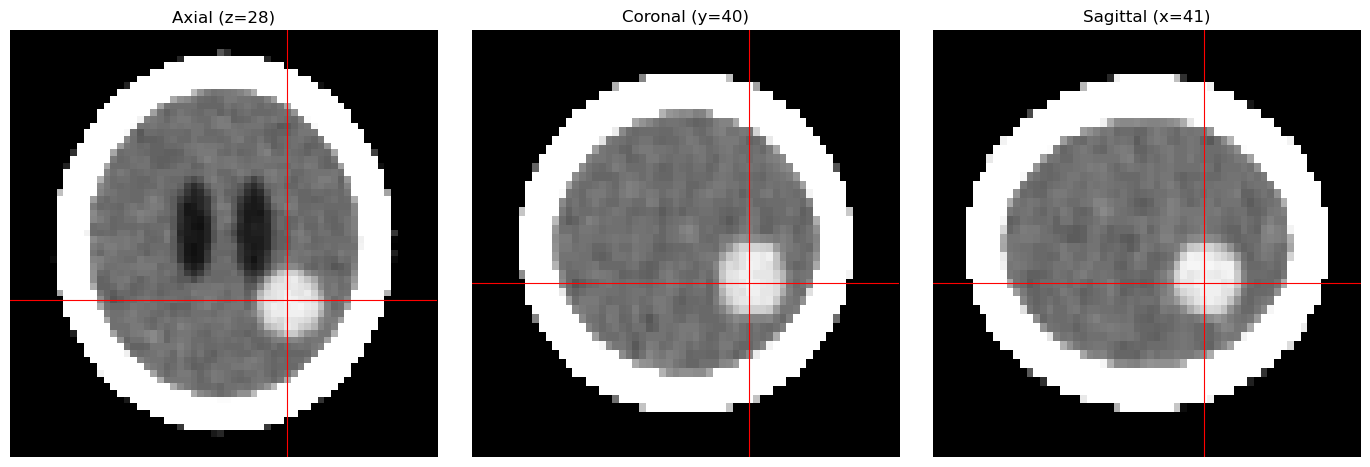

centroid (np.int64(28), np.int64(40), np.int64(41)); distance from evaluation centroid: 2.92 mm


In [17]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2
component_labels, n_components = ndimage.label(candidates)
component_sizes = np.bincount(component_labels.ravel())
component_sizes[0] = 0
lesion = component_labels == component_sizes.argmax()
cz, cy, cx = np.rint(ndimage.center_of_mass(lesion)).astype(int)

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

slice_data = [vol[cz, :, :], vol[:, cy, :], vol[:, :, cx]]
slice_titles = [f"Axial (z={cz})", f"Coronal (y={cy})", f"Sagittal (x={cx})"]
slice_aspects = [1, ASPECT, ASPECT]
for ax, image, title, aspect in zip(axes, slice_data, slice_titles, slice_aspects):
    ax.imshow(window(image, 80, 40), cmap="gray", vmin=0, vmax=1, aspect=aspect)
    ax.axhline(cy if title.startswith("Axial") else (cz if title.startswith("Coronal") or title.startswith("Sagittal") else 0), color="r", lw=0.8)
    ax.axvline(cx if title.startswith("Axial") or title.startswith("Coronal") else cy, color="r", lw=0.8)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
centroid_distance_mm = np.linalg.norm((np.array([cz, cy, cx]) - truth_centroid) * np.array(SPACING))
print(f"centroid {cz, cy, cx}; distance from evaluation centroid: {centroid_distance_mm:.2f} mm")

**Reflection:** Why was erosion needed?

**Your answer:** Voxels near the skull can contain a mixture of bone, tissue, and background because of the partial-volume effect.
Those mixed voxels may have intensities similar to the tumour and create false candidates.
Erosion removes the uncertain boundary shell, leaving a safer interior region for lesion detection.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


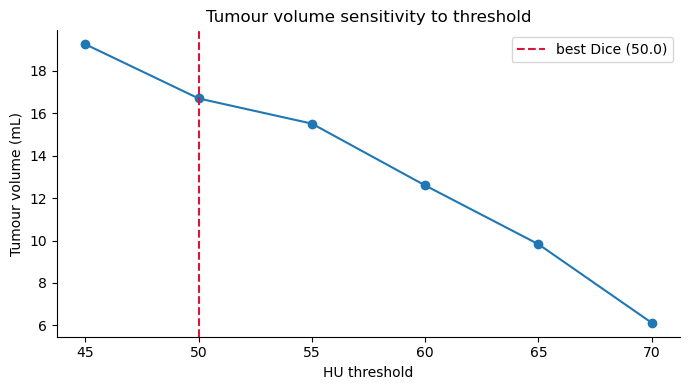

Report volume range: 6.12-19.26 mL


In [18]:
truth = labels == 5
rows = []
# TODO 1 & 2
for threshold in [45, 50, 55, 60, 65, 70]:
    threshold_mask = vol > threshold
    components, _ = ndimage.label(threshold_mask)
    component_id = components[cz, cy, cx]
    segmented = components == component_id
    voxel_count = int(segmented.sum())
    dice = 2 * np.logical_and(segmented, truth).sum() / (segmented.sum() + truth.sum())
    rows.append({"threshold": threshold, "voxels": voxel_count,
                 "volume_ml": voxel_count * VOXEL_MM3 / 1000, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold"], table["volume_ml"], marker="o")
best = table.loc[table["dice"].idxmax()]
ax.axvline(best["threshold"], color="crimson", ls="--", label=f"best Dice ({best['threshold']})")
ax.set_xlabel("HU threshold")
ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Tumour volume sensitivity to threshold")
ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Report volume range: {table['volume_ml'].min():.2f}-{table['volume_ml'].max():.2f} mL")

**Reflection:** How would you choose and show the tumour threshold in real life?

**Your answer:** I would compare several thresholds with radiologist markings and choose a value that is clinically consistent, not just the one with the largest volume.
I would show the volume range from the tested thresholds and overlay the segmentation on the CT slices.
This makes the uncertainty visible instead of presenting one threshold as an exact fact.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

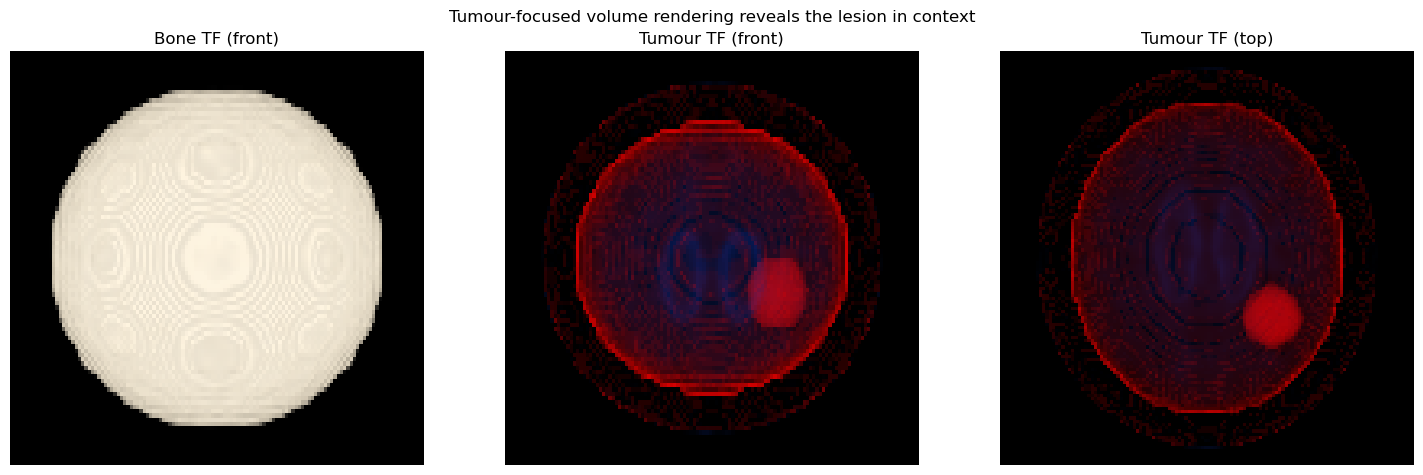

In [19]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (4, (0, 0, 0), 0.0),
    (20, (0.1, 0.3, 1.0), 0.015),
    (45, (0, 0, 0), 0.0),
    (54, (0, 0, 0), 0.0),
    (55, (1.0, 0.0, 0.0), 0.08),
    (90, (1.0, 0.0, 0.0), 0.08),
    (91, (0, 0, 0), 0.0),
    (200, (0, 0, 0), 0.0),
    (399, (0, 0, 0), 0.0),
    (400, (0, 0, 0), 0.005),
    (1500, (0, 0, 0), 0.005),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
bone_color, bone_alpha = render(vol, bone_tf, axis=1)
front_color, front_alpha = render(vol, tumour_tf, axis=1)
top_color, top_alpha = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(bone_color, 0, 1), aspect=ASPECT)
axes[0].set_title("Bone TF (front)")
axes[1].imshow(np.clip(front_color, 0, 1), aspect=ASPECT)
axes[1].set_title("Tumour TF (front)")
axes[2].imshow(np.clip(top_color, 0, 1), aspect=1)
axes[2].set_title("Tumour TF (top)")
for ax in axes:
    ax.set_axis_off()

# TODO 4: suptitle
fig.suptitle("Tumour-focused volume rendering reveals the lesion in context")
plt.tight_layout(); plt.show()

**Reflection:** Why might a faint red rim appear, and how could it be removed?

**Your answer:** The rim is caused by occlusion and overlapping intensity ranges, where partial-volume voxels near the skull receive a small tumour colour or opacity.
A segmentation mask or clipping/cropping step can remove those unwanted voxels before rendering.
A transfer function alone cannot always separate materials that share similar intensity values.


## Task 5 — The Decision (No Code)

**Your final note:** The lesion is near voxel position `(z=28, y=40, x=41)`, and its threshold-based volume ranges from about 6.12 to 19.26 mL.
I would open the meeting with the three-plane MPR because slicing exposes internal structure and shows the lesion clearly without skull occlusion.
The segmentation overlay should then confirm the measured region, while the 3D render can show its wider context.
The 3D view is useful, but its appearance depends on the transfer function and may hide structures behind the skull.


In [20]:
import os, base64, io
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage

os.makedirs("pbi_data/slices", exist_ok=True)

# ---------- 1) tissue summary ----------------------------------------
names = {0:"Air",1:"Scalp",2:"Bone",3:"Brain",4:"CSF",5:"Tumour"}
colors = {0:"#9AA0A6",1:"#F1C27D",2:"#E8E2D0",3:"#F2A9A9",4:"#5B8DEF",5:"#D9534F"}
rows = []
for lbl in np.unique(labels):
    m = labels == lbl
    rows.append(dict(label=int(lbl), tissue=names[int(lbl)],
                     count=int(m.sum()),
                     volume_ml=m.sum()*VOXEL_MM3/1000,
                     mean_hu=float(vol[m].mean()),
                     min_hu =float(vol[m].min()),
                     max_hu =float(vol[m].max()),
                     color=colors[int(lbl)]))
pd.DataFrame(rows).to_csv("pbi_data/dim_tissue.csv", index=False)

# ---------- 2) threshold sensitivity ---------------------------------
truth = labels == 5
tz, ty, tx = np.rint(ndimage.center_of_mass(truth)).astype(int)
sens = []
for c in [45,50,55,60,65,70]:
    comp,_ = ndimage.label(vol > c)
    reg = comp == comp[tz,ty,tx]
    dice = 2*(reg & truth).sum()/(reg.sum()+truth.sum())
    sens.append(dict(threshold=c, voxels=int(reg.sum()),
                     volume_ml=reg.sum()*VOXEL_MM3/1000, dice=dice))
pd.DataFrame(sens).to_csv("pbi_data/threshold_sensitivity.csv", index=False)

# ---------- 3) lesion centroid / scan meta --------------------------
pd.DataFrame([dict(
    cz=tz, cy=ty, cx=tx,
    cz_mm=tz*SPACING[0], cy_mm=ty*SPACING[1], cx_mm=tx*SPACING[2],
    tumour_voxels=int(truth.sum()),
    tumour_volume_ml=truth.sum()*VOXEL_MM3/1000,
    scan_voxels=int(vol.size),
    scan_mm3=vol.size*VOXEL_MM3,
    scan_mb_16bit=vol.size*2/1024**2,
    tumour_volume_min_ml=min(s["volume_ml"] for s in sens),
    tumour_volume_max_ml=max(s["volume_ml"] for s in sens),
    best_threshold=max(sens, key=lambda s:s["dice"])["threshold"],
    best_dice=max(s["dice"] for s in sens)
)]).to_csv("pbi_data/scan_meta.csv", index=False)

# ---------- 4) pre-rendered slices (PNG saved to disk) --------------
def save_slice(img, name):
    fig, ax = plt.subplots(figsize=(3,3))
    ax.imshow(np.clip(img,-20,100), cmap="gray", origin="lower"); ax.axis("off")
    fig.savefig(f"pbi_data/slices/{name}.png", bbox_inches="tight", pad_inches=0, dpi=120)
    plt.close(fig)

slice_index = []
for z in range(NZ):
    save_slice(vol[z], f"ax_{z:02d}");       slice_index.append(dict(view="Axial", idx=z))
for y in range(NY):
    save_slice(vol[:,y,:], f"co_{y:02d}");   slice_index.append(dict(view="Coronal", idx=y))
for x in range(NX):
    save_slice(vol[:,:,x], f"sa_{x:02d}");   slice_index.append(dict(view="Sagittal", idx=x))
pd.DataFrame(slice_index).to_csv("pbi_data/slice_index.csv", index=False)

# ---------- 5) 3-D renders from Task 4 (PNG saved to disk) ----------
# (reuse the notebook cell that produced bone_color, front_color, top_color)
def save_rgb(arr, name):
    fig, ax = plt.subplots(figsize=(3,3))
    ax.imshow(np.clip(arr,0,1)); ax.axis("off")
    fig.savefig(f"pbi_data/{name}.png", bbox_inches="tight", pad_inches=0, dpi=120)
    plt.close(fig)
save_rgb(bone_color, "render_bone")
save_rgb(front_color,"render_tumour_front")
save_rgb(top_color,  "render_tumour_top")

# ---------- 6) transfer-function control points ---------------------
pd.DataFrame([
    dict(hu=-1000, r=0, g=0, b=0, alpha=0.0),
    dict(hu=-200 , r=0, g=0, b=0, alpha=0.0),
    dict(hu=-50  , r=.9,g=.7,  b=.6, alpha=.02),
    dict(hu=30   , r=.95,g=.75,b=.65,alpha=.004),
    dict(hu=45   , r=.95,g=.75,b=.65,alpha=.004),
    dict(hu=60   , r=1, g=.1,  b=.1, alpha=.15),
    dict(hu=80   , r=1, g=.1,  b=.1, alpha=.15),
    dict(hu=100  , r=.9,g=.9,  b=.9, alpha=0.0),
    dict(hu=300  , r=1, g=1,   b=.95,alpha=.015),
    dict(hu=1500 , r=1, g=1,   b=1,  alpha=.025),
]).to_csv("pbi_data/tf_curve.csv", index=False)

In [21]:
import matplotlib.pyplot as plt
import numpy as np

def save_scan(img, filename):
    fig, ax = plt.subplots(figsize=(4, 4))
    # Apply the Brain Window (W=80, L=40) using the clip function from the notebook
    ax.imshow(np.clip(img, 0, 80), cmap="gray", origin="lower")
    ax.axis("off")
    # Save it perfectly cropped
    fig.savefig(filename, bbox_inches="tight", pad_inches=0, dpi=150)
    plt.close(fig)

# 1. Axial (z=28)
save_scan(vol[28, :, :], "mpr_axial.png")

# 2. Coronal (y=40)
save_scan(vol[:, 40, :], "mpr_coronal.png")

# 3. Sagittal (x=41)
save_scan(vol[:, :, 41], "mpr_sagittal.png")

print("Images saved successfully!")

Images saved successfully!


In [22]:
import matplotlib.pyplot as plt
import numpy as np

def save_render(arr, filename):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(np.clip(arr, 0, 1))
    ax.axis("off")
    fig.savefig(filename, bbox_inches="tight", pad_inches=0, dpi=200)
    plt.close(fig)

# Assuming bone_color, front_color, and top_color are still in memory from the notebook
save_render(bone_color, "render_bone.png")
save_render(front_color, "render_tumour_front.png")
save_render(top_color, "render_tumour_top.png")
print("3D Renders saved!")

3D Renders saved!
